[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_3_Analisis_Exploratorio.ipynb)

# Fase 3. Análisis exploratorio de datos

Describo el conjunto de entrenamiento con cinco propiedades fisicoquímicas: peso molecular, MolLogP, donantes, aceptores y TPSA. La fase 2 calculó 217 descriptores escalares de RDKit; el CSV también incluye la variable derivada `LipinskiViolations`, por eso el resumen de variables numéricas muestra 218. Mantengo test reservado para evaluar los modelos.

## 3.1. Lectura de los datos

Leo los CSV preparados en la fase anterior desde la carpeta pública del proyecto. Así puedo ejecutar este notebook sin subir archivos manualmente.

In [1]:
%pip -q install rdkit


In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
dilist['nombre_normalizado'] = dilist['CompoundName'].astype('string').str.strip().str.casefold()  # Quito espacios laterales para evitar falsos no encontrados.
estructuras['nombre_normalizado'] = estructuras['CompoundName'].astype('string').str.strip().str.casefold()  # Creo la misma clave normalizada en el mapa.
datos = dilist.merge(estructuras.drop(columns='CompoundName'), on='nombre_normalizado', how='left')  # Uno por nombre normalizado sin perder la etiqueta original.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /content/datos_dili
Descriptores numéricos disponibles: 218


## 3.2. Resumen univariado

Para cada descriptor calculo media, mediana, moda, desviación estándar, mínimo, máximo y cuartiles. También cuento las etiquetas DILI en valores absolutos y relativos.

In [3]:
# Selecciono cinco propiedades fisicoquímicas fáciles de interpretar.
variables = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Escojo las variables de Lipinski y TPSA.
variables = [variable for variable in variables if variable in train_df.columns]  # Confirmo que estén en el conjunto.

# Calculo las medidas de resumen univariado con entrenamiento.
resumen = train_df[variables].describe().T  # Obtengo media, desviación, mínimo, cuartiles y máximo.
resumen['mediana'] = train_df[variables].median()  # Añado la mediana.
resumen['moda'] = train_df[variables].mode().iloc[0]  # Añado la moda más frecuente.
display(resumen.round(2))  # Muestro el resumen redondeado.
print('Lectura de las medidas:')  # Inicio el comentario de los resultados calculados.
for variable in variables:  # Recorro las propiedades estudiadas.
    print(f"{variable}: mediana {resumen.loc[variable, 'mediana']:.2f}; la mitad central está entre {resumen.loc[variable, '25%']:.2f} y {resumen.loc[variable, '75%']:.2f}.")  # Interpreto centro y dispersión observados.

# Cuento las clases DILI en frecuencia absoluta y relativa.
frecuencias = train_df['DILI'].value_counts().sort_index().to_frame('frecuencia')  # Cuento registros por clase.
frecuencias['porcentaje'] = (100 * frecuencias['frecuencia'] / len(train_df)).round(1)  # Calculo porcentajes.
frecuencias.index = frecuencias.index.map({0: 'DILI negativa', 1: 'DILI positiva'})  # Pongo nombres legibles.
display(frecuencias)  # Muestro la distribución de clases.
print(f"En train, {frecuencias.loc['DILI positiva', 'porcentaje']:.1f}% tiene etiqueta positiva y {frecuencias.loc['DILI negativa', 'porcentaje']:.1f}% negativa.")  # Comento el balance observado.


,count,mean,std,min,25%,50%,75%,max,mediana,moda
MolWt,947.0,414.58,463.20,18.02,257.33,329.37,429.56,7053.95,329.37,135.21
MolLogP,947.0,1.76,3.86,-49.12,0.70,2.36,3.70,9.91,2.36,-3.59
NumHDonors,947.0,2.89,6.89,0.00,1.00,2.00,3.00,100.00,2.00,1.00
NumHAcceptors,947.0,5.70,7.10,0.00,3.00,4.00,6.00,99.00,4.00,3.00
TPSA,947.0,110.85,200.33,0.00,45.24,74.60,115.17,2912.95,74.60,3.24


Lectura de las medidas:
MolWt: mediana 329.37; la mitad central está entre 257.33 y 429.56.
MolLogP: mediana 2.36; la mitad central está entre 0.70 y 3.70.
NumHDonors: mediana 2.00; la mitad central está entre 1.00 y 3.00.
NumHAcceptors: mediana 4.00; la mitad central está entre 3.00 y 6.00.
TPSA: mediana 74.60; la mitad central está entre 45.24 y 115.17.


,frecuencia,porcentaje
DILI,,
DILI negativa,365,38.5
DILI positiva,582,61.5


En train, 61.5% tiene etiqueta positiva y 38.5% negativa.


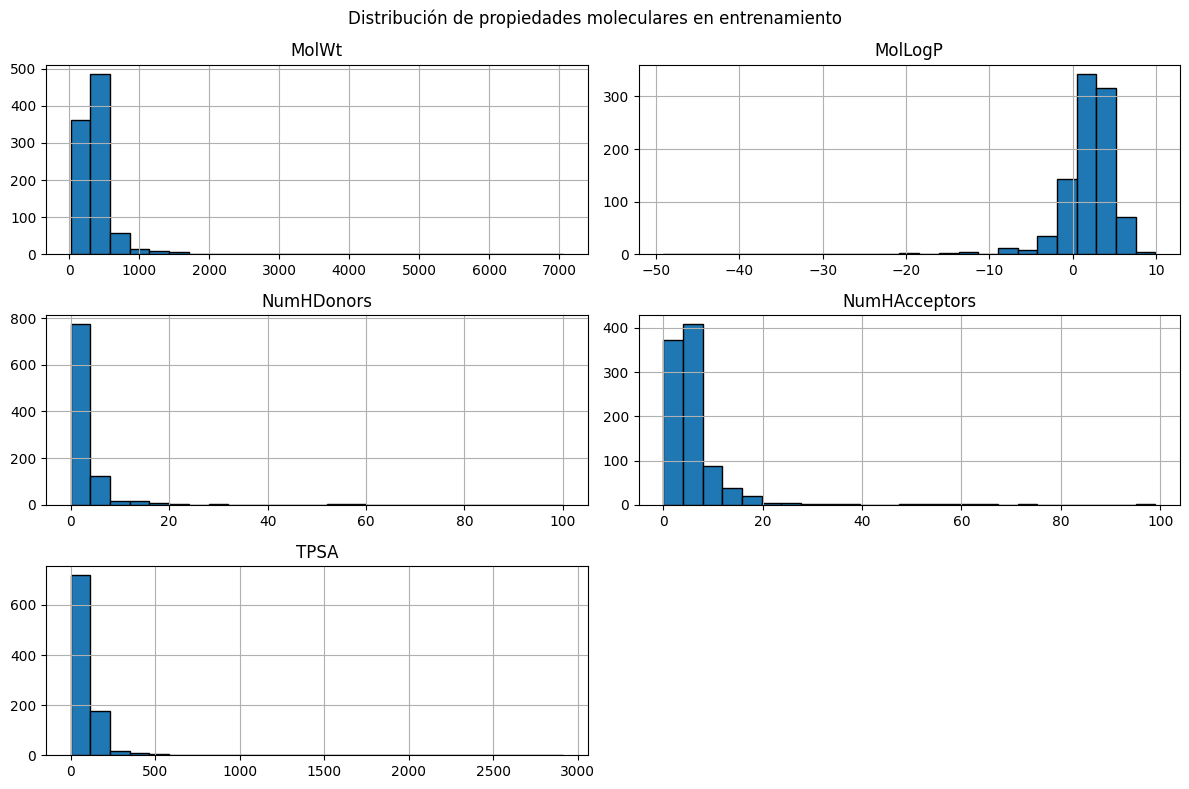

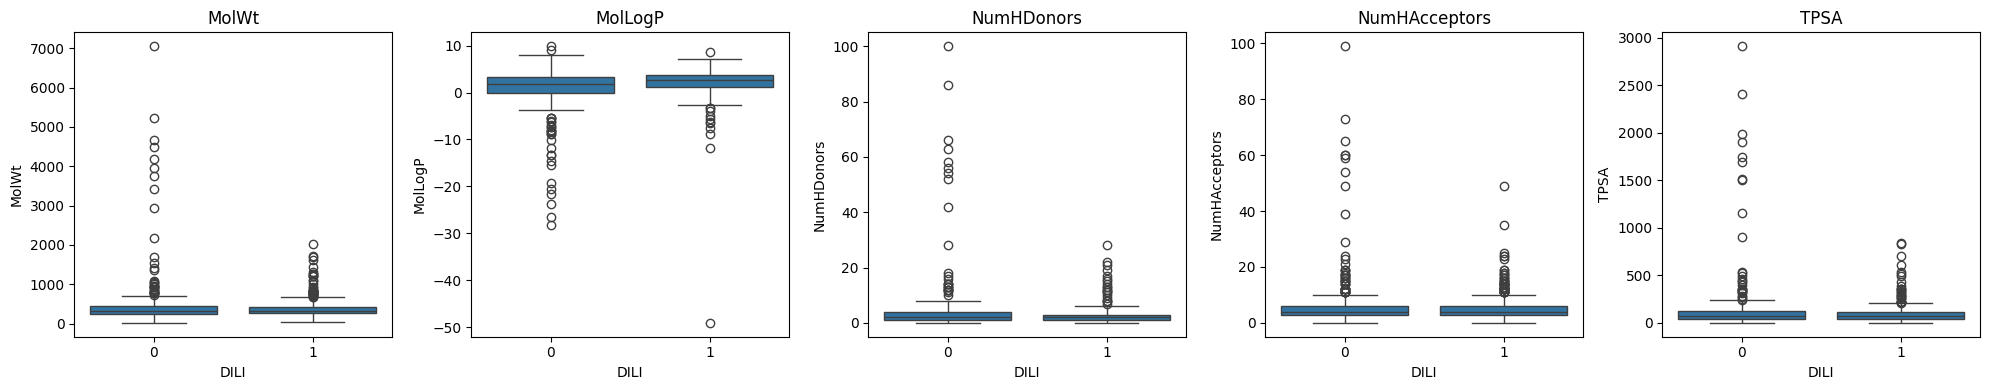

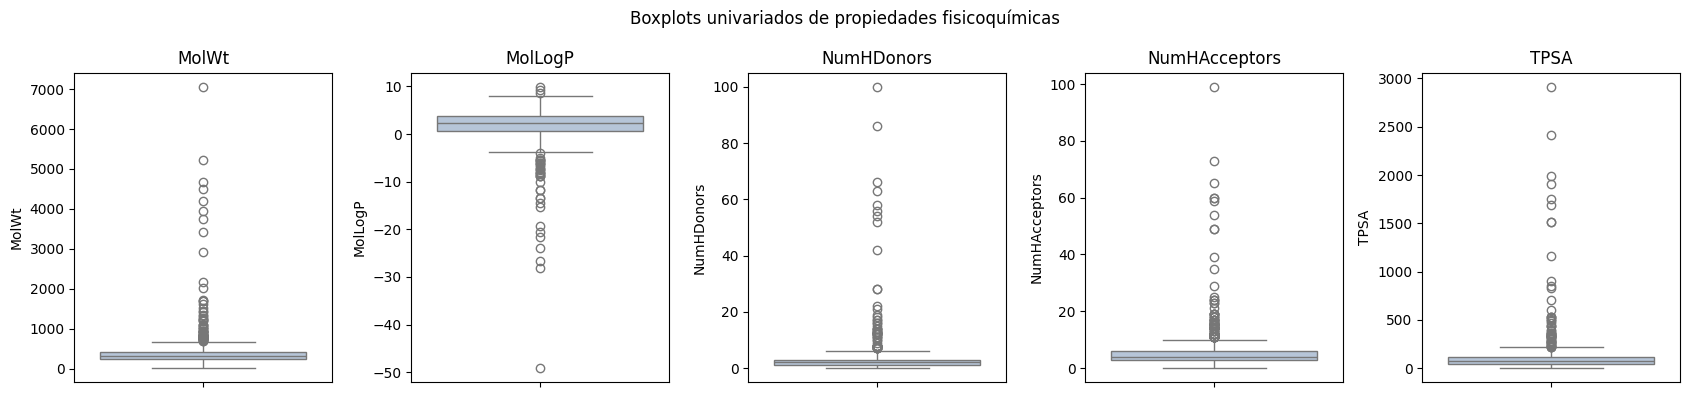

Los puntos fuera de los bigotes son observaciones que el criterio 1,5 × RIC marca para el análisis de extremos.
MolWt: mediana DILI negativa = 324.38; positiva = 331.98.
MolLogP: mediana DILI negativa = 1.86; positiva = 2.62.
NumHDonors: mediana DILI negativa = 2.00; positiva = 2.00.
NumHAcceptors: mediana DILI negativa = 4.00; positiva = 4.00.
TPSA: mediana DILI negativa = 74.68; positiva = 74.58.


In [4]:
# Importo herramientas para dibujar histogramas y diagramas de caja.
import matplotlib.pyplot as plt  # Creo gráficos.
import seaborn as sns  # Dibujo comparaciones por clase.

# Represento la forma de las distribuciones de cada descriptor.
train_df[variables].hist(figsize=(12, 8), bins=25, edgecolor='black')  # Dibujo un histograma por variable.
plt.suptitle('Distribución de propiedades moleculares en entrenamiento')  # Titulo la figura.
plt.tight_layout()  # Ajusto los espacios entre gráficos.
plt.show()  # Muestro los histogramas.

# Comparo cada propiedad entre las dos clases de DILI.
fig, axes = plt.subplots(1, len(variables), figsize=(4 * len(variables), 4))  # Creo un panel de diagramas.
for ax, variable in zip(axes, variables):  # Recorro cada descriptor y su eje.
    sns.boxplot(data=train_df, x='DILI', y=variable, ax=ax)  # Dibujo cajas por clase.
    ax.set_title(variable)  # Pongo el nombre del descriptor.
plt.tight_layout()  # Acomodo los títulos.
plt.show()  # Muestro las comparaciones.

# Represento boxplots univariados para ver medianas, dispersión y extremos.
fig, axes = plt.subplots(1, len(variables), figsize=(3.4 * len(variables), 4))  # Creo un panel por propiedad.
for ax, variable in zip(axes, variables):  # Recorro los descriptores seleccionados.
    sns.boxplot(y=train_df[variable], ax=ax, color='lightsteelblue', showfliers=True)  # Dibujo caja y observaciones extremas.
    ax.set_title(variable)  # Identifico la propiedad representada.
    ax.set_xlabel('')  # Quito una etiqueta que no aporta información.
plt.suptitle('Boxplots univariados de propiedades fisicoquímicas')  # Titulo la figura.
plt.tight_layout()  # Ajusto el espacio entre paneles.
plt.show()  # Muestro los boxplots individuales.
print('Los puntos fuera de los bigotes son observaciones que el criterio 1,5 × RIC marca para el análisis de extremos.')  # Explico el boxplot.
for variable in variables:  # Comparo las medianas que aparecen en los boxplots por clase.
    medianas_clase = train_df.groupby('DILI')[variable].median()  # Calculo una mediana para cada etiqueta.
    print(f"{variable}: mediana DILI negativa = {medianas_clase.get(0, np.nan):.2f}; positiva = {medianas_clase.get(1, np.nan):.2f}.")  # Comento la diferencia observada.



## 3.3. Calidad de los datos y valores atípicos

Reviso nulos, duplicados y posibles valores atípicos. Uso el criterio de 1,5 veces el rango intercuartílico (RIC) en MolWt, MolLogP, donantes, aceptores y TPSA. Calculo los límites con train y retiro de train y test cualquier compuesto que quede fuera en al menos una propiedad. Antes del filtro, muestro algunas estructuras para revisar qué tipo de compuestos identifica.

In [5]:
# Calculo los valores ausentes y los duplicados antes de filtrar.
calidad = pd.DataFrame({'nulos': datos_limpios.isna().sum(), 'porcentaje_nulos': (100 * datos_limpios.isna().mean()).round(1)})  # Resumo valores ausentes.
display(calidad.sort_values('porcentaje_nulos', ascending=False).head(12))  # Muestro primero las columnas con más nulos.
print('Nombres sin estructura inequívoca:', datos['InChIKey'].isna().sum())  # Informo cobertura de estructuras.
print('Nombres repetidos en DILIst:', dilist['CompoundName'].duplicated().sum())  # Cuento nombres repetidos.
print('InChIKey repetidas en train:', train_df['InChIKey'].duplicated().sum())  # Compruebo duplicados químicos.
print('Filas con etiquetas contradictorias:', len(datos_conflicto))  # Muestro posibles conflictos.

# Calculo límites de 1,5 × RIC solo con train.
q1 = train_df[variables].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_df[variables].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
lim_inf = q1 - 1.5 * ric  # Defino límites inferiores.
lim_sup = q3 + 1.5 * ric  # Defino límites superiores.
fuera_train = train_df[variables].lt(lim_inf) | train_df[variables].gt(lim_sup)  # Marco extremos por variable en train.
fuera_test = test_df[variables].lt(lim_inf) | test_df[variables].gt(lim_sup)  # Aplico a test los mismos límites.
tabla_outliers = pd.DataFrame({'límite inferior': lim_inf, 'límite superior': lim_sup, 'train': fuera_train.sum(), 'test': fuera_test.sum()})  # Organizo umbrales y recuentos.
tabla_outliers['train (%)'] = (100 * tabla_outliers['train'] / len(train_df)).round(1)  # Calculo porcentaje en train.
tabla_outliers['test (%)'] = (100 * tabla_outliers['test'] / len(test_df)).round(1)  # Calculo porcentaje en test.
display(tabla_outliers.round(2))  # Muestro los resultados.
mask_outlier_train = fuera_train.any(axis=1)  # Marco compuestos fuera de rango en al menos una propiedad.
mask_outlier_test = fuera_test.any(axis=1)  # Aplico la misma regla a test.
print(f"Train: retiro {mask_outlier_train.sum()} de {len(train_df)} compuestos ({100 * mask_outlier_train.mean():.1f}%).")  # Cuantifico la retirada.
print(f"Test: retiro {mask_outlier_test.sum()} de {len(test_df)} compuestos ({100 * mask_outlier_test.mean():.1f}%).")  # Cuantifico la retirada.
print('Calculo los límites solo con train y los aplico sin recalcularlos a test.')  # Explico el control de las particiones.


,nulos,porcentaje_nulos
Routes_of_Administration,252,21.3
BCUT2D_MWLOW,31,2.6
BCUT2D_CHGHI,31,2.6
BCUT2D_CHGLO,31,2.6
BCUT2D_LOGPHI,31,2.6
BCUT2D_LOGPLOW,31,2.6
BCUT2D_MRHI,31,2.6
BCUT2D_MRLOW,31,2.6
BCUT2D_MWHI,31,2.6
MinPartialCharge,3,0.3


Nombres sin estructura inequívoca: 95
Nombres repetidos en DILIst: 0
InChIKey repetidas en train: 0
Filas con etiquetas contradictorias: 0


,límite inferior,límite superior,train,test,train (%),test (%)
MolWt,-1.01,687.90,69,24,7.3,10.1
MolLogP,-3.82,8.22,38,15,4.0,6.3
NumHDonors,-2.00,6.00,56,14,5.9,5.9
NumHAcceptors,-1.50,10.50,92,26,9.7,11.0
TPSA,-59.66,220.06,54,13,5.7,5.5


Train: retiro 115 de 947 compuestos (12.1%).
Test: retiro 36 de 237 compuestos (15.2%).
Calculo los límites solo con train y los aplico sin recalcularlos a test.


### Lectura de calidad y extremos

En la tabla molecular hay 1.184 registros. La vía de administración tiene 252 valores ausentes (21,3 %); ocho descriptores BCUT2D presentan 31 ausencias cada uno (2,6 %) y tres descriptores de carga parcial tienen tres cada uno (0,3 %). De los 1.279 nombres de DILIst, 95 no quedaron asociados a una estructura. No encontré nombres repetidos, InChIKey duplicadas en train ni etiquetas contradictorias.

Los límites calculados con train fueron: MolWt de −1,01 a 687,90; MolLogP de −3,82 a 8,22; donantes de −2 a 6; aceptores de −1,5 a 10,5; y TPSA de −59,66 a 220,06. Marco como extremo un compuesto que rebasa al menos uno de esos límites. El filtro retira 115 de 947 observaciones de train (12,1 %) y 36 de 237 de test (15,2 %). El ejemplo mostrado, fondaparinux sodium, rebasa los cinco límites. Un valor extremo no demuestra por sí solo que el registro sea erróneo; aquí se excluye porque el análisis posterior se definió para el intervalo restante.

,CompoundName,DILI,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,criterio
558,fondaparinux sodium,1,1728.09,-49.12,9.0,49.0,833.78,"MolWt, MolLogP, NumHDonors, NumHAcceptors, TPSA"


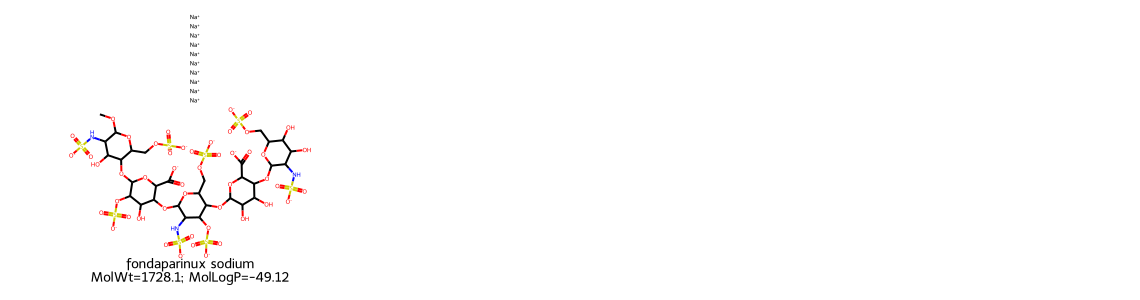

La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.


In [6]:
# Selecciono tres compuestos de train marcados por el filtro.
compuestos_atipicos = train_df.loc[mask_outlier_train].copy()  # Reúno las filas que se retirarán.
nombres_ejemplo = ['atazanavir', 'montelukast', 'fondaparinux sodium']  # Elijo perfiles moleculares distintos.
ejemplos_atipicos = compuestos_atipicos[compuestos_atipicos['CompoundName'].str.casefold().isin(nombres_ejemplo)].copy()  # Localizo los ejemplos.
ejemplos_atipicos['criterio'] = ejemplos_atipicos.apply(lambda fila: ', '.join([v for v in variables if fuera_train.loc[fila.name, v]]), axis=1)  # Indico qué propiedad excede el límite.
columnas_ejemplo = ['CompoundName', 'DILI', 'MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA', 'criterio']  # Selecciono los datos a mostrar.
display(ejemplos_atipicos[columnas_ejemplo].round(2))  # Muestro sus valores.

# Dibujo las estructuras junto al nombre, peso molecular y MolLogP.
from rdkit import Chem  # Leo moléculas desde SMILES.
from rdkit.Chem import Draw  # Dibujo las estructuras químicas.
moleculas = []  # Guardo estructuras válidas.
leyendas = []  # Guardo las etiquetas de cada dibujo.
for _, fila in ejemplos_atipicos.iterrows():  # Recorro los compuestos escogidos.
    mol = Chem.MolFromSmiles(fila['SMILES'])  # Construyo una molécula desde SMILES.
    if mol is not None:  # Compruebo que RDKit la reconoce.
        moleculas.append(mol)  # Añado la estructura.
        leyendas.append(f"{fila['CompoundName']}\nMolWt={fila['MolWt']:.1f}; MolLogP={fila['MolLogP']:.2f}")  # Identifico el dibujo.
if moleculas:  # Compruebo que haya estructuras válidas.
    display(Draw.MolsToGridImage(moleculas, molsPerRow=3, subImgSize=(380, 300), legends=leyendas))  # Muestro las tres juntas.
print('La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.')  # Interpreto los ejemplos.


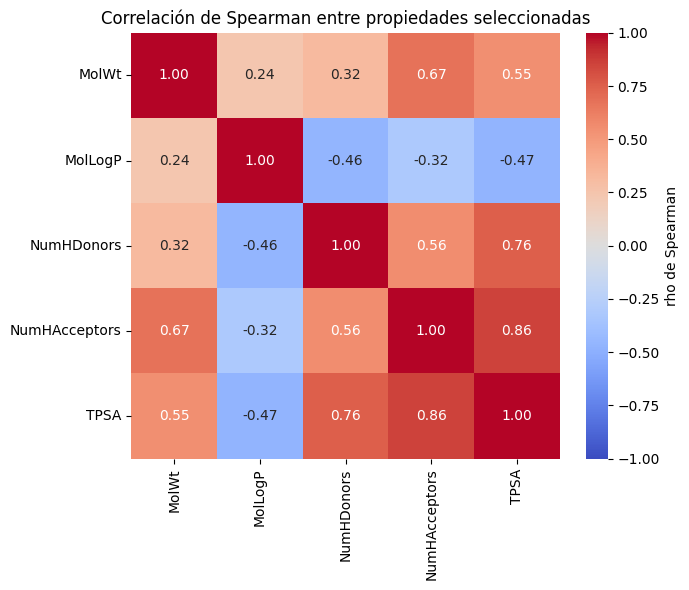

,descriptor,Spearman con DILI,n observaciones
0,FractionCSP3,-0.201484,947
1,BCUT2D_MRHI,0.181120,924
2,fr_Al_OH,-0.167608,947
3,BCUT2D_LOGPLOW,0.165538,924
4,MolLogP,0.163735,947
5,SlogP_VSA2,-0.159672,947
6,PEOE_VSA1,-0.148576,947
7,fr_quatN,-0.145857,947
8,SMR_VSA6,-0.141473,947
9,NumUnspecifiedAtomStereoCenters,-0.140836,947


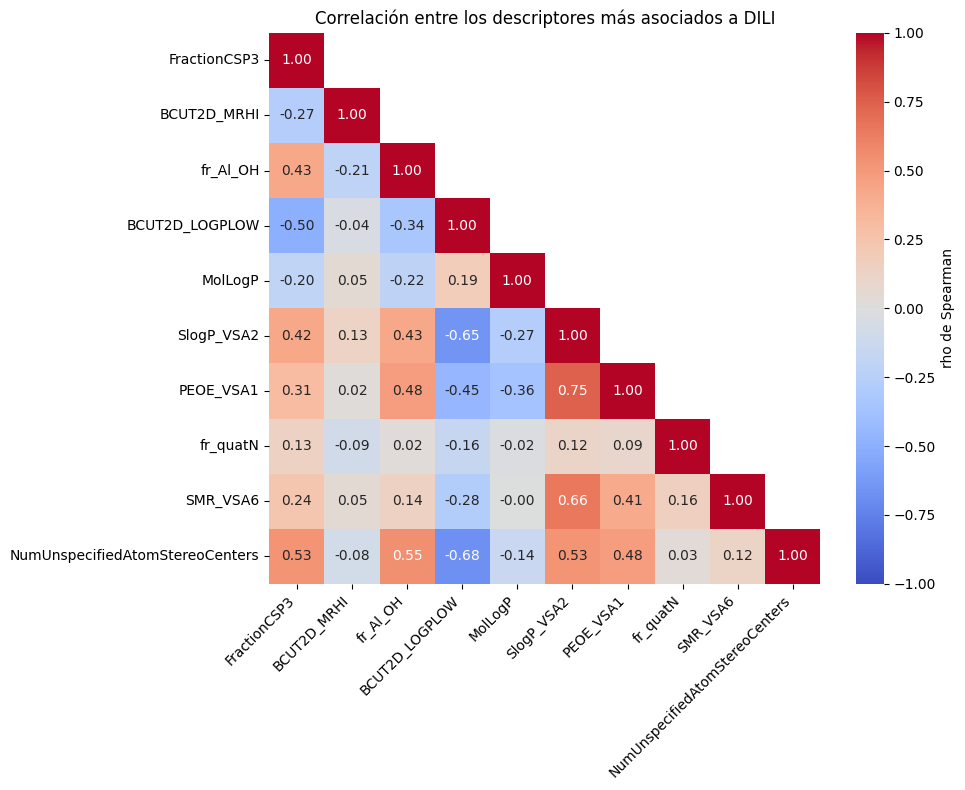

DILI,0,1,diferencia positiva-negativa
MolWt,324.38,331.98,7.60
MolLogP,1.86,2.62,0.77
TPSA,74.68,74.58,-0.10
NumHDonors,2.00,2.00,0.00
NumHAcceptors,4.00,4.00,0.00


,Spearman con DILI
MolLogP,0.163735
NumHDonors,-0.069520
NumHAcceptors,-0.046134
TPSA,-0.032231
MolWt,0.004663


Entre las cinco propiedades, MolLogP tiene la mayor asociación monotónica con DILI (rho = 0.16).
Las correlaciones describen asociaciones; no demuestran causalidad.


In [7]:
# Calculo la correlación entre las cinco propiedades fisicoquímicas del EDA.
correlaciones = train_df[variables].corr(method='spearman')  # Calculo Spearman con entrenamiento.
fig, ax = plt.subplots(figsize=(7, 6))  # Creo una figura independiente para esta matriz.
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Represento una sola barra de color.
ax.set_title('Correlación de Spearman entre propiedades seleccionadas')  # Titulo el mapa.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Muestro la matriz.

# Reviso la asociación de los descriptores con DILI y retiro columnas con demasiados valores ausentes.
variables_amplias = [variable for variable in DESCRIPTORES if variable not in ['DILI', 'DILIST_ID'] and train_df[variable].notna().mean() >= 0.80 and train_df[variable].nunique(dropna=True) > 1]  # Filtro propiedades con suficientes observaciones.
correlacion_dili = train_df[variables_amplias + ['DILI']].corr(method='spearman', min_periods=100)['DILI'].drop('DILI').dropna()  # Calculo asociación con al menos cien pares.
top_asociaciones = correlacion_dili.abs().sort_values(ascending=False).head(15)  # Selecciono las quince asociaciones mayores.
resumen_asociaciones = pd.DataFrame({'descriptor': top_asociaciones.index, 'Spearman con DILI': correlacion_dili.loc[top_asociaciones.index].values, 'n observaciones': train_df[top_asociaciones.index].notna().sum().values})  # Añado el tamaño de cada comparación.
display(resumen_asociaciones)  # Muestro las asociaciones y sus tamaños.

# Represento la correlación entre los diez descriptores con mayor asociación a DILI.
top_diez = top_asociaciones.head(10).index.tolist()  # Selecciono diez variables para la matriz.
matriz_amplia = train_df[top_diez].corr(method='spearman', min_periods=100)  # Calculo correlaciones con al menos cien observaciones comunes.
fig, ax = plt.subplots(figsize=(10, 8))  # Creo una segunda figura independiente.
mascara = np.triu(np.ones_like(matriz_amplia, dtype=bool), k=1)  # Oculto la mitad superior repetida.
sns.heatmap(matriz_amplia, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Dibujo una matriz legible con una barra.
ax.set_title('Correlación entre los descriptores más asociados a DILI')  # Titulo la segunda matriz.
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')  # Giro los nombres para que no se solapen.
plt.tight_layout()  # Ajusto etiquetas y márgenes.
plt.show()  # Muestro la matriz amplia.

# Comparo las medianas de las cinco propiedades del EDA entre las clases DILI.
medianas = train_df.groupby('DILI')[variables].median().T  # Calculo medianas por clase.
medianas['diferencia positiva-negativa'] = medianas[1] - medianas[0]  # Calculo una diferencia descriptiva.
display(medianas.sort_values('diferencia positiva-negativa', key=abs, ascending=False).round(2))  # Ordeno por diferencia absoluta.

# Calculo la asociación de las cinco propiedades seleccionadas con DILI.
relacion = train_df[variables + ['DILI']].corr(method='spearman')['DILI'].drop('DILI')  # Extraigo la correlación con la etiqueta.
display(relacion.sort_values(key=abs, ascending=False).to_frame('Spearman con DILI'))  # Muestro las asociaciones seleccionadas.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación de mayor magnitud.
print(f"Entre las cinco propiedades, {variable_mayor} tiene la mayor asociación monotónica con DILI (rho = {relacion[variable_mayor]:.2f}).")  # Comento signo y magnitud observados.
print('Las correlaciones describen asociaciones; no demuestran causalidad.')  # Aclaro su alcance.


In [8]:
# Resumo el balance de etiquetas antes del filtro.
proporciones = train_df['DILI'].value_counts(normalize=True)  # Calculo proporciones originales.
print(f"Antes del filtro, DILI positiva representa {100 * proporciones.get(1, 0):.1f}% y DILI negativa {100 * proporciones.get(0, 0):.1f}% de train.")  # Explico el balance.

# Comparo las medianas originales de MolLogP por clase.
medianas_logp = train_df.groupby('DILI')['MolLogP'].median()  # Calculo una mediana por clase.
print(f"Antes del filtro, la mediana de MolLogP es {medianas_logp.get(1, np.nan):.2f} en DILI positiva y {medianas_logp.get(0, np.nan):.2f} en DILI negativa.")  # Comparo ambas clases.

# Resumo la asociación y el tamaño que queda para las fases siguientes.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación absoluta más alta.
print(f"La mayor asociación entre las cinco propiedades es {variable_mayor} (rho = {relacion[variable_mayor]:.2f}).")  # Comento el resultado.
print(f"Tras el filtro quedan {len(train_df) - mask_outlier_train.sum()} compuestos en train y {len(test_df) - mask_outlier_test.sum()} en test.")  # Informo el tamaño posterior.
print('Estas relaciones son asociaciones y no permiten concluir causalidad.')  # Delimito el alcance.


Antes del filtro, DILI positiva representa 61.5% y DILI negativa 38.5% de train.
Antes del filtro, la mediana de MolLogP es 2.62 en DILI positiva y 1.86 en DILI negativa.
La mayor asociación entre las cinco propiedades es MolLogP (rho = 0.16).
Tras el filtro quedan 832 compuestos en train y 201 en test.
Estas relaciones son asociaciones y no permiten concluir causalidad.


## ¿Qué nos dicen los datos?

El conjunto de entrenamiento contiene 947 compuestos: 582 (61,5 %) tienen etiqueta DILI positiva y 365 (38,5 %) negativa. Las medianas por clase son próximas para cuatro de las cinco propiedades: MolWt es 324,38 en negativos y 331,98 en positivos; los donantes son 2 en ambas clases; los aceptores son 4; y TPSA es 74,68 frente a 74,58. MolLogP presenta la mayor diferencia entre estas propiedades, con medianas de 1,86 y 2,62, respectivamente.

La asociación de MolLogP con la etiqueta es débil (rho de Spearman = 0,164). Donantes (−0,070), aceptores (−0,046), TPSA (−0,032) y MolWt (0,005) muestran asociaciones aún menores. Entre los descriptores calculados, las mayores asociaciones observadas también son modestas: FractionCSP3 (−0,201) y BCUT2D_MRHI (0,181). Por tanto, ninguna propiedad aislada separa bien las clases. La matriz de correlación sirve para detectar redundancia entre descriptores, que reviso antes de interpretar los coeficientes de los modelos.

El filtro de 1,5 × RIC, con límites calculados solo en train y aplicados sin recalcular a test, deja 832 compuestos en train y 201 en test. Las distribuciones muestran colas largas y valores extremos; fondaparinux sodium es el ejemplo visible con valores fuera de rango en las cinco propiedades. El filtro es una decisión analítica, no una afirmación de que esos fármacos sean errores o deban descartarse en un contexto farmacológico.

La cobertura estructural limita el análisis: 95 de los 1.279 nombres no tienen estructura asociada. En los registros moleculares, faltan 252 valores de vía de administración (21,3 %). No aparecen nombres repetidos en DILIst ni etiquetas contradictorias entre las estructuras coincidentes. Estos resultados describen la composición de DILIst y las propiedades calculadas; no estiman directamente el riesgo clínico de un medicamento.